# BÀI 1: PHÂN LOẠI ẢNH DỰA TRÊN ĐẶC TRƯNG THỐNG KÊ VÀ MÀU SẮC
**Mục tiêu:** Trích chọn các đặc trưng thống kê cơ bản từ ảnh số (Mean, Std trên RGB/HSV, Histogram màu HSV, Entropy ảnh xám), biểu diễn ảnh bằng vector đặc trưng, xây dựng và đánh giá mô hình KNN và SVM trên bộ dữ liệu 3 nhóm quả: **Táo (`apple`), Chuối (`banana`), Cam (`orange`)** từ `fruits-360-100x100`.

## Yêu cầu 1: Tiền xử lý ảnh (Đọc, thay đổi kích thước về 128×128 và chuyển RGB sang HSV)

Nhóm APPLE: 30 thư mục con
Nhóm BANANA: 6 thư mục con
Nhóm ORANGE: 6 thư mục con


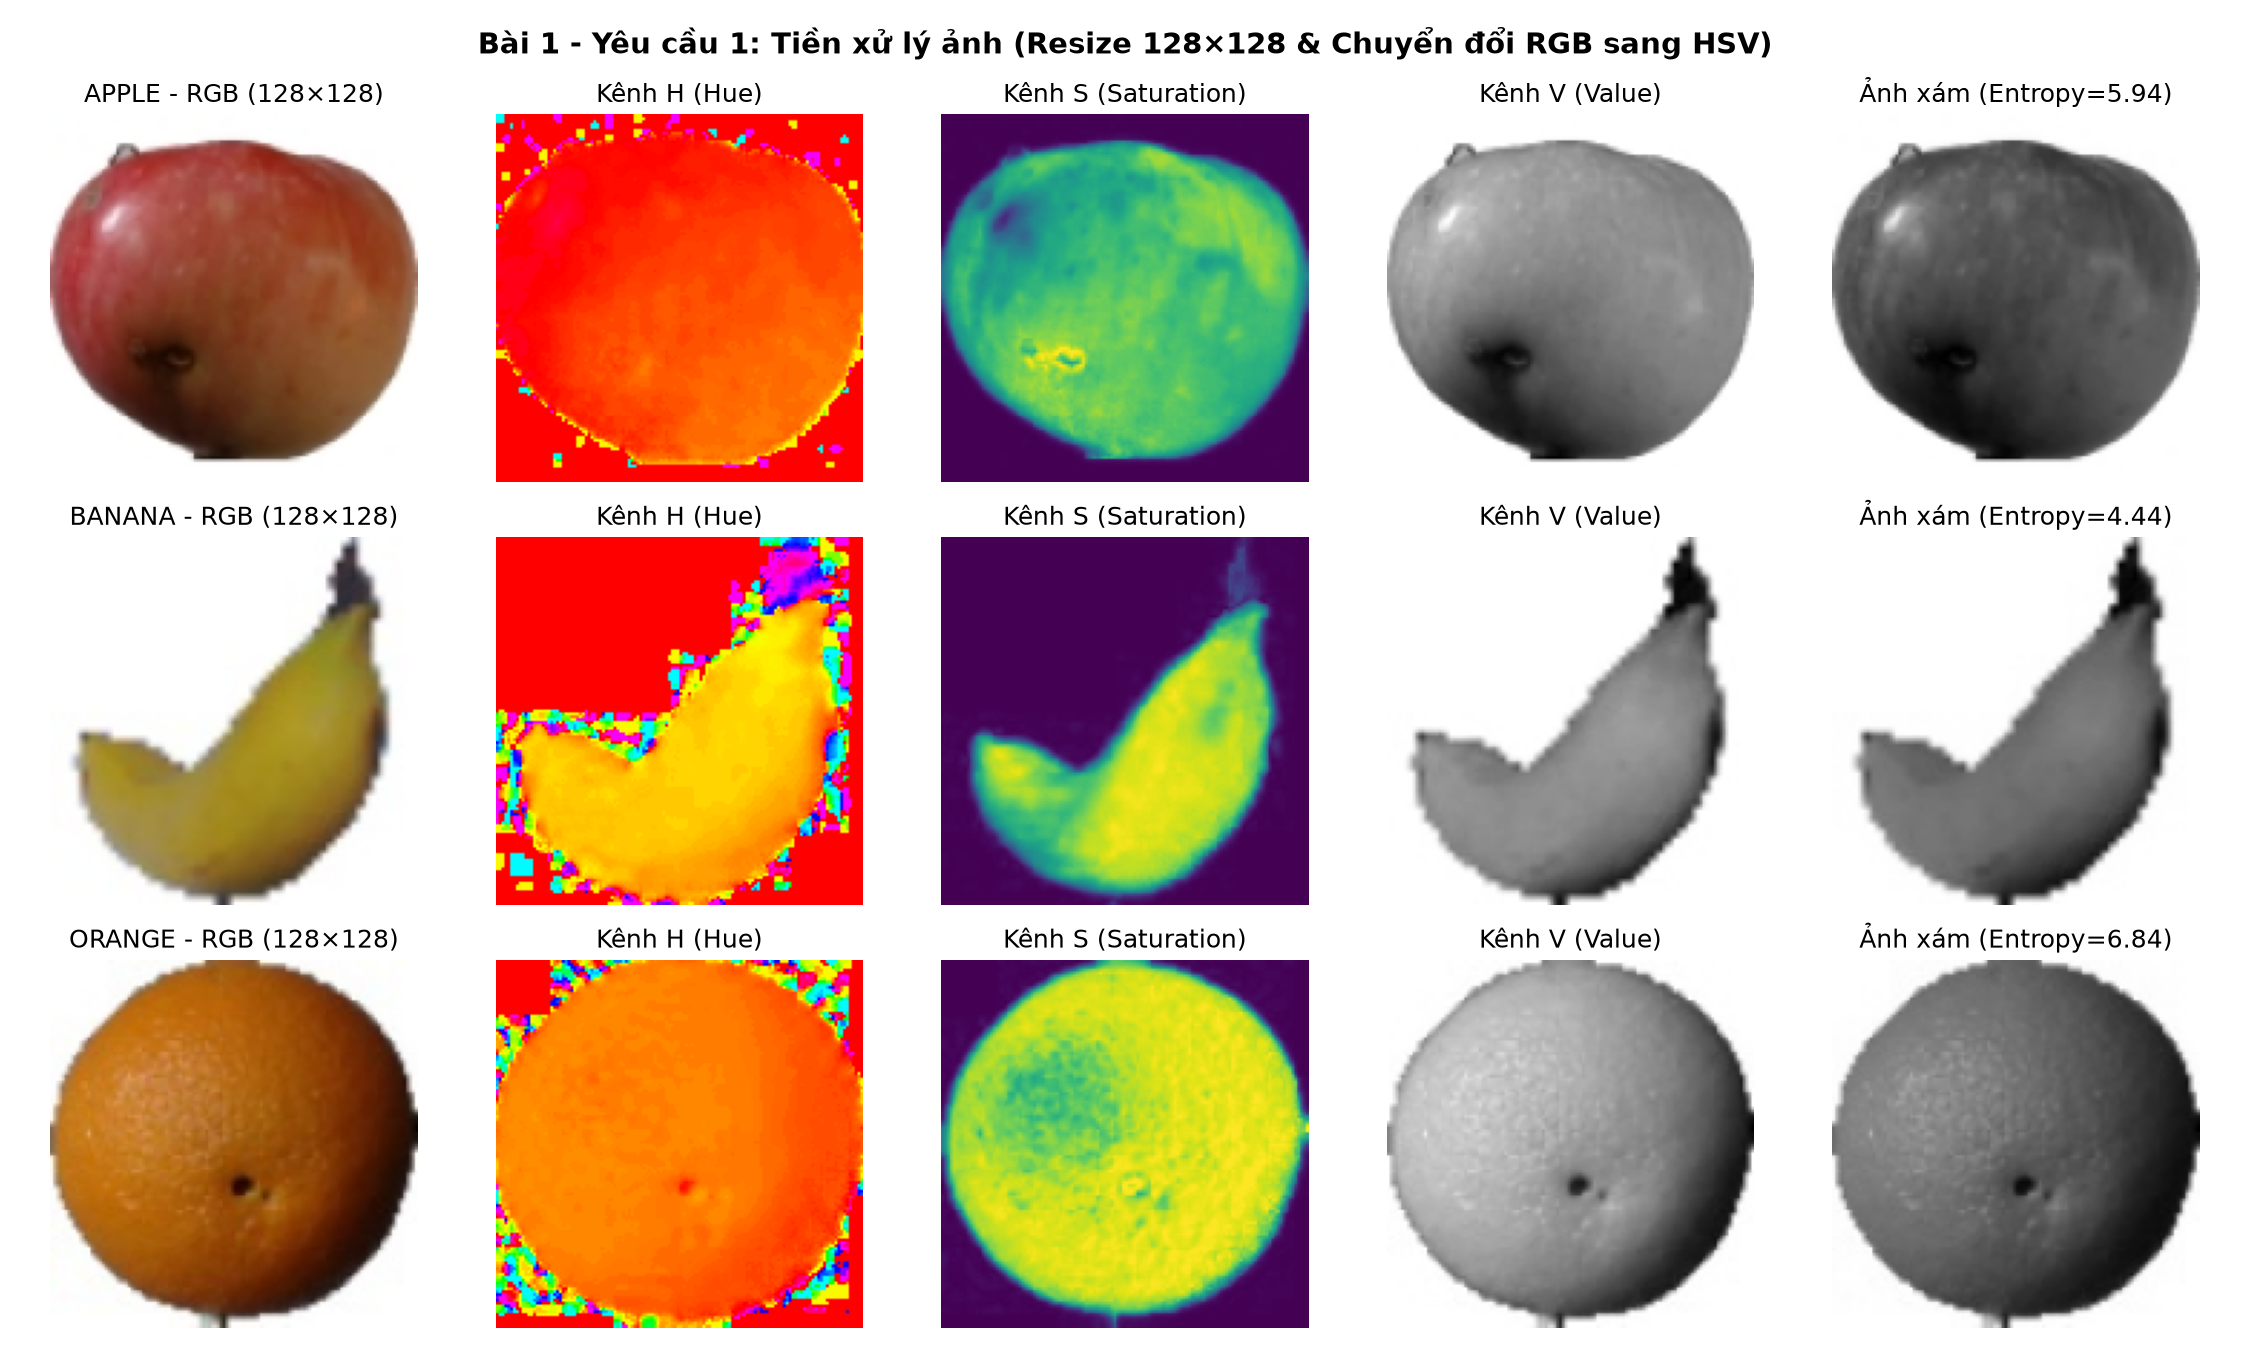

In [1]:
from bai1_color_stats import discover_fruit_folders, sample_fruit_dataset, preprocess_image
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

folders = discover_fruit_folders("fruits-360-100x100")
for k, v in folders.items():
    print(f"Nhóm {k.upper()}: {len(v)} thư mục con")

img = mpimg.imread("outputs/bai1/fig1_preprocessing_rgb_hsv.png")
plt.figure(figsize=(15, 9))
plt.imshow(img)
plt.axis("off")
plt.show()

## Yêu cầu 2: Trích chọn đặc trưng (Mean + Std mỗi kênh màu, Histogram HSV, Entropy ảnh xám)
- **Mean + Std (RGB):** 6 chiều (`R_mean, G_mean, B_mean, R_std, G_std, B_std`)
- **Mean + Std (HSV):** 6 chiều (`H_mean, S_mean, V_mean, H_std, S_std, V_std`)
- **Histogram màu HSV:** 32 chiều (H: 16 bins, S: 8 bins, V: 8 bins chuẩn hóa L1)
- **Entropy ảnh xám:** 1 chiều ($H = -\sum p_i \log_2(p_i)$)
- **Vector kết hợp toàn bộ:** 45 chiều

Tổng số mẫu: 1800 ảnh (Mỗi lớp 600 ảnh) | Số chiều đặc trưng: 45

 label sub_folder     R_mean     G_mean     B_mean    H_mean     S_mean     V_mean  Gray_Entropy
 apple   Apple 10 170.823059 123.750366 109.199341 16.704285 118.882568 170.827881      5.937571
 apple   Apple 10 171.498230 131.759216 118.745361 10.635254 111.557617 171.505493      5.597856
 apple   Apple 10 159.157471 111.382568 104.106262 11.479126 125.763855 159.164551      5.942091
banana   Banana 1 210.412292 202.067078 172.844055 25.086182  64.319763 210.609741      4.436051
banana   Banana 1 198.227966 188.050537 167.163208 22.786499  62.998840 198.605469      4.526279
banana   Banana 1 231.458374 226.505859 209.464111 11.752441  36.213135 231.553833      2.794096
orange   Orange 1 171.653259 120.978333  73.890015 19.296082 169.009033 171.771973      6.842752
orange   Orange 1 168.783752 127.113892  79.625427 22.340637 159.492004 168.958435      6.913718
orange   Orange 1 177.997437 118.490234  69.666077 19.700378 

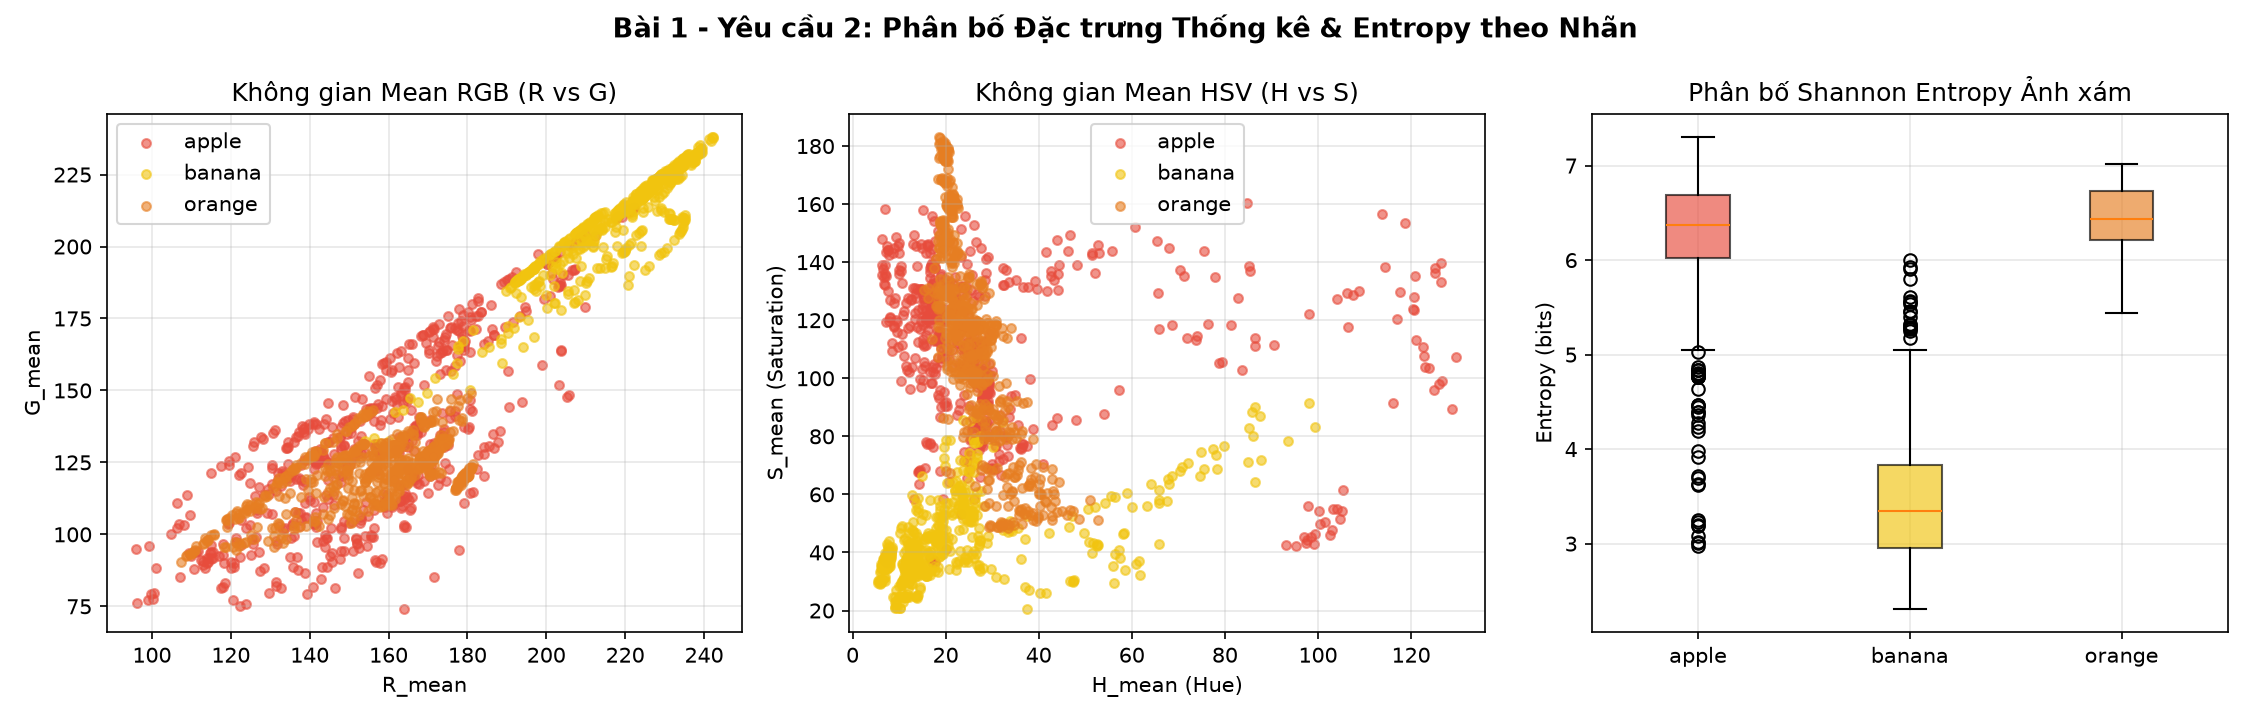

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

df_feat = pd.read_csv("outputs/bai1/bai1_features.csv")
preview_cols = ["label", "sub_folder", "R_mean", "G_mean", "B_mean", "H_mean", "S_mean", "V_mean", "Gray_Entropy"]
print(f"Tổng số mẫu: {len(df_feat)} ảnh (Mỗi lớp 600 ảnh) | Số chiều đặc trưng: 45\n")
print(df_feat[preview_cols].groupby("label").head(3).to_string(index=False))

img = mpimg.imread("outputs/bai1/fig2_feature_distributions.png")
plt.figure(figsize=(15, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

## Yêu cầu 3 & 4: Xây dựng mô hình, Đánh giá 4 Thí nghiệm (TN1–TN4) & Confusion Matrix
- Chia `Train/Test = 80/20` có phân tầng (`stratify=label`, `random_state=42`).
- Chuẩn hóa `StandardScaler` chỉ `fit` trên tập `Train` và `transform` trên `Train` & `Test`.

=== KẾT QUẢ ĐÁNH GIÁ 4 THÍ NGHIỆM (TN1 - TN4) ===
Experiment                  Features  Num_Dims Model  Accuracy  Precision  Recall  F1-score
       TN1          Mean + Std (RGB)         6   KNN    0.9694     0.9720  0.9694    0.9694
       TN2          Mean + Std (HSV)         6   KNN    0.9722     0.9733  0.9722    0.9721
       TN3         Histogram màu HSV        32   SVM    0.9917     0.9917  0.9917    0.9917
       TN4 Kết hợp toàn bộ đặc trưng        45   SVM    0.9917     0.9917  0.9917    0.9917


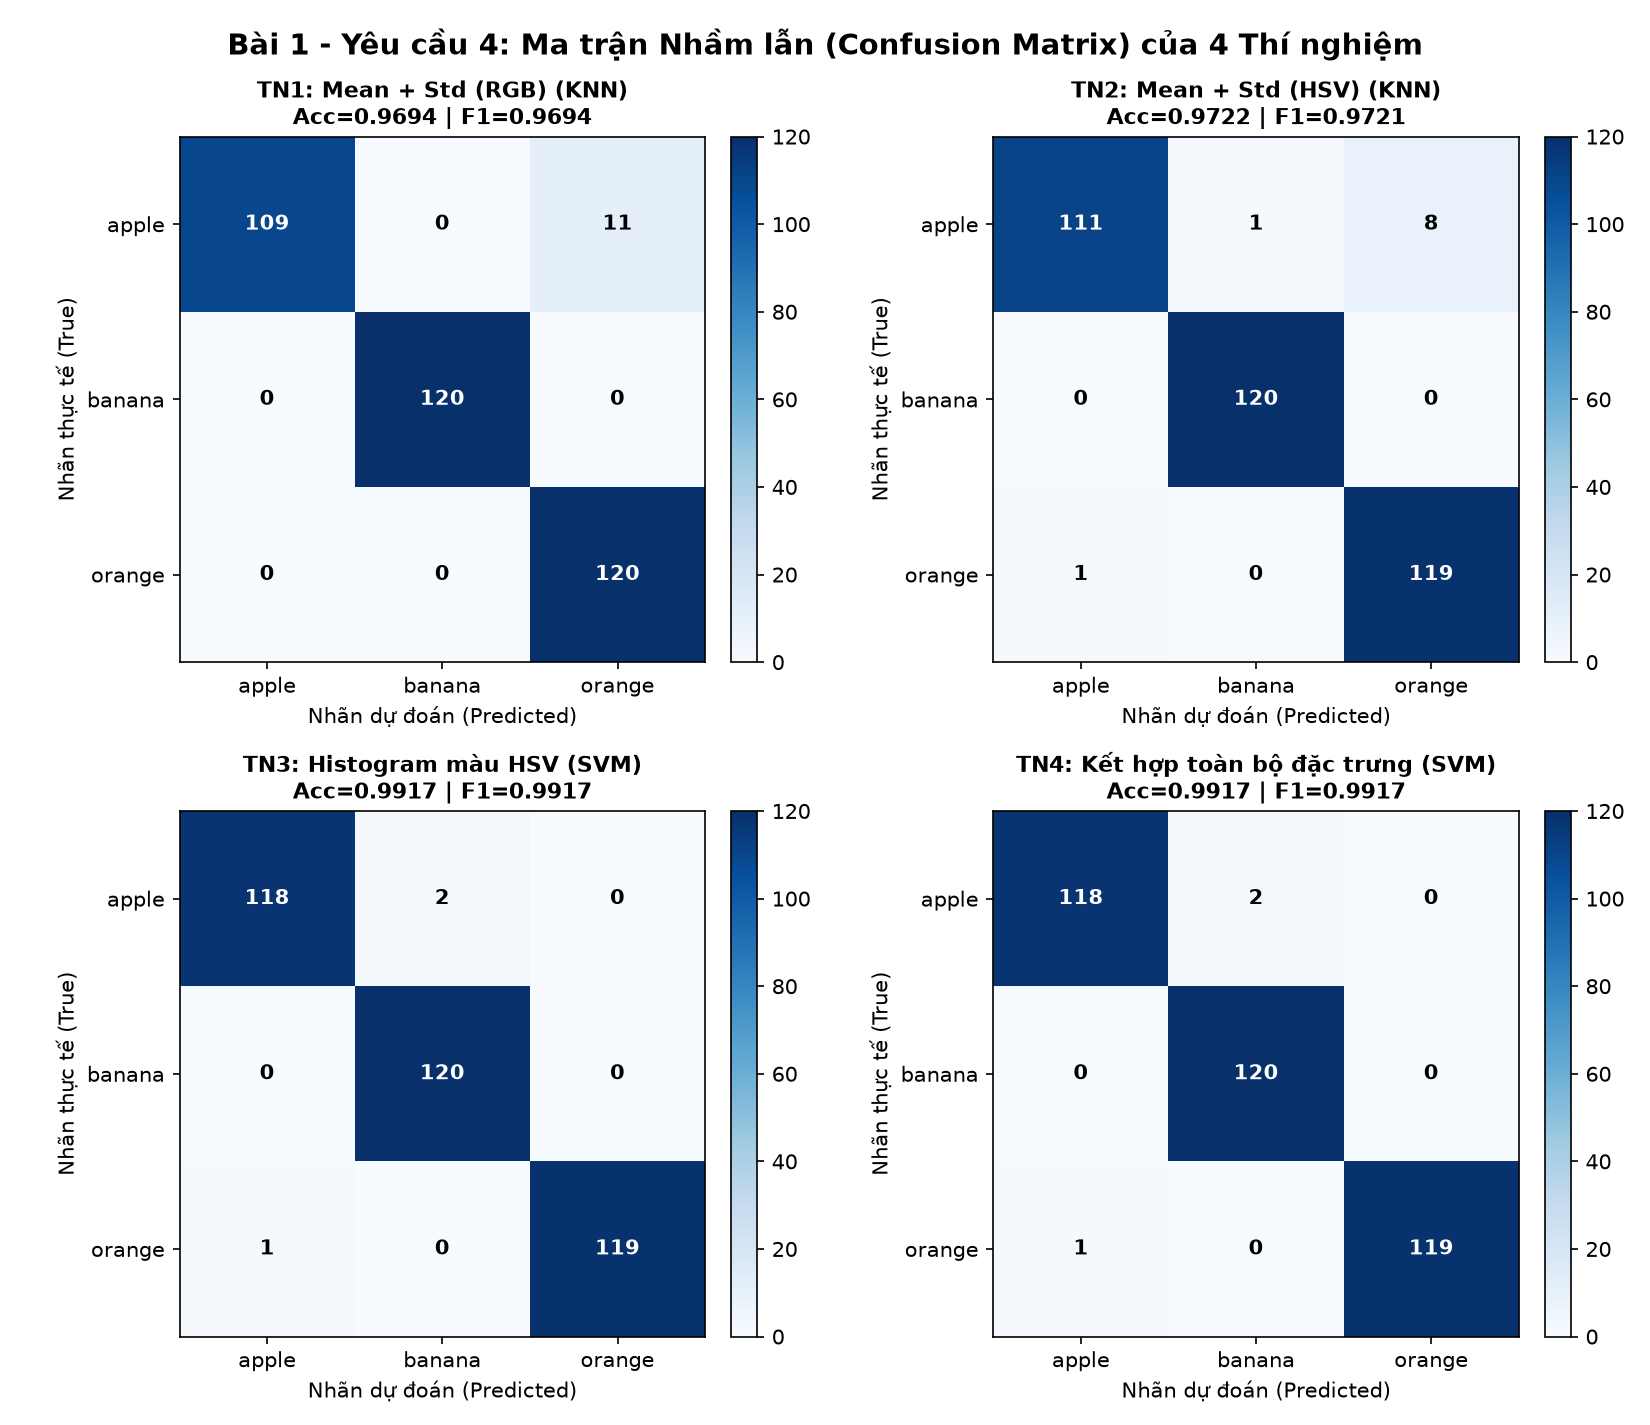

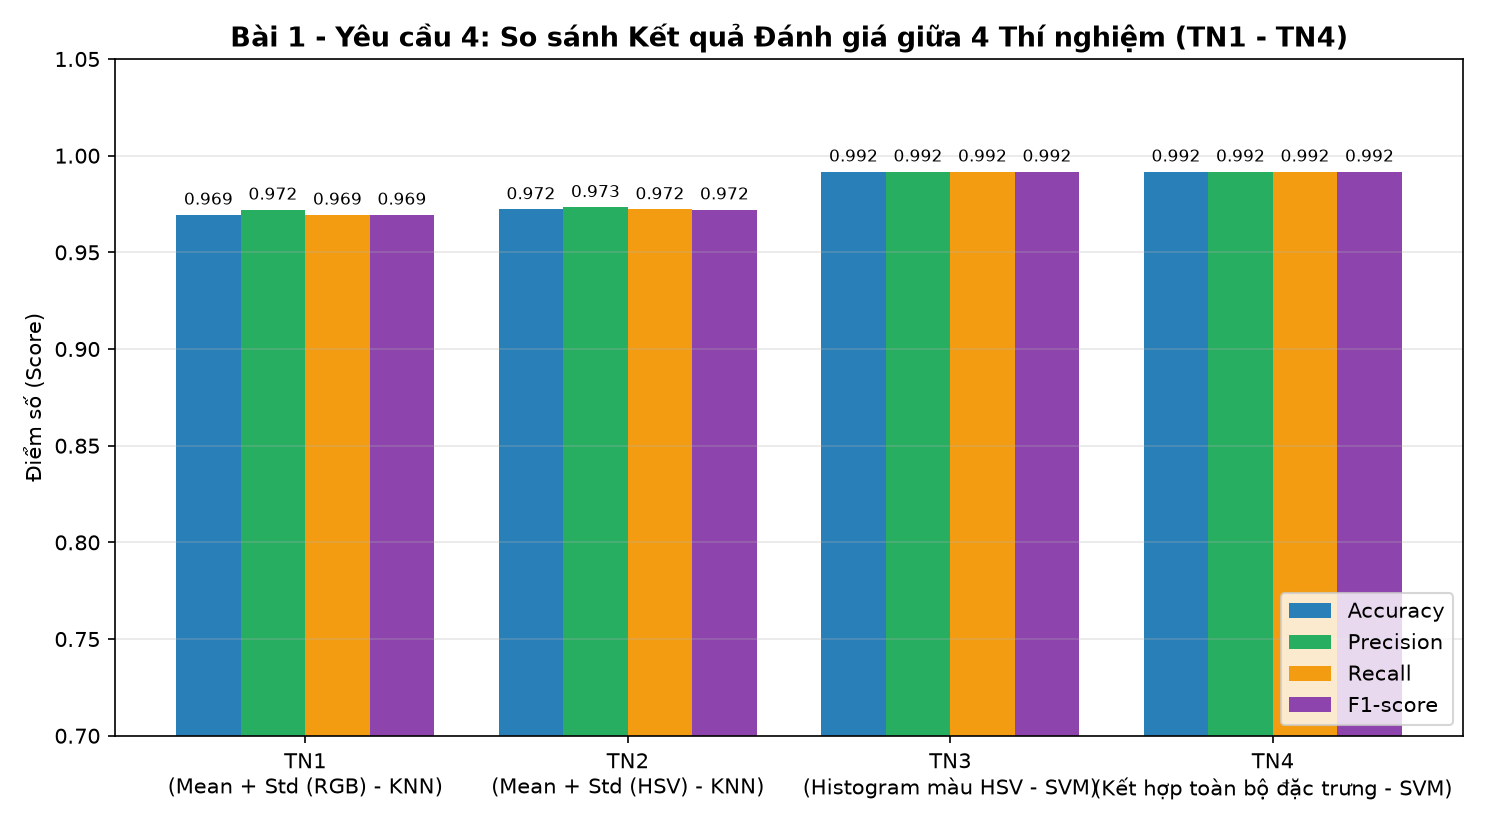

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

df_metrics = pd.read_csv("outputs/bai1/bai1_metrics.csv")
print("=== KẾT QUẢ ĐÁNH GIÁ 4 THÍ NGHIỆM (TN1 - TN4) ===")
print(df_metrics.to_string(index=False))

for fig_file in ["outputs/bai1/fig3_confusion_matrices.png", "outputs/bai1/fig4_metrics_comparison.png"]:
    img = mpimg.imread(fig_file)
    plt.figure(figsize=(11, 8))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

## Dự đoán nhãn cho ảnh mới (Unseen Images)

=== DỰ ĐOÁN NHÃN CHO ẢNH MỚI (UNSEEN IMAGES) ===
          sub_folder true_label TN1_KNN_RGB TN2_KNN_HSV TN3_SVM_HistHSV TN4_SVM_All
             Apple 9      apple       apple       apple           apple       apple
      Apple Golden 1      apple       apple       apple           apple       apple
             Apple 7      apple       apple       apple           apple       apple
         Apple Red 2      apple       apple       apple           apple       apple
            Banana 3     banana      banana      banana          banana      banana
Banana Lady Finger 1     banana      banana      banana          banana      banana
        Banana Red 1     banana      banana      banana          banana      banana
            Banana 4     banana      banana      banana          banana      banana
            Orange 3     orange      orange      orange          orange      orange
            Orange 2     orange      orange      orange          orange      orange
            Orange 5     or

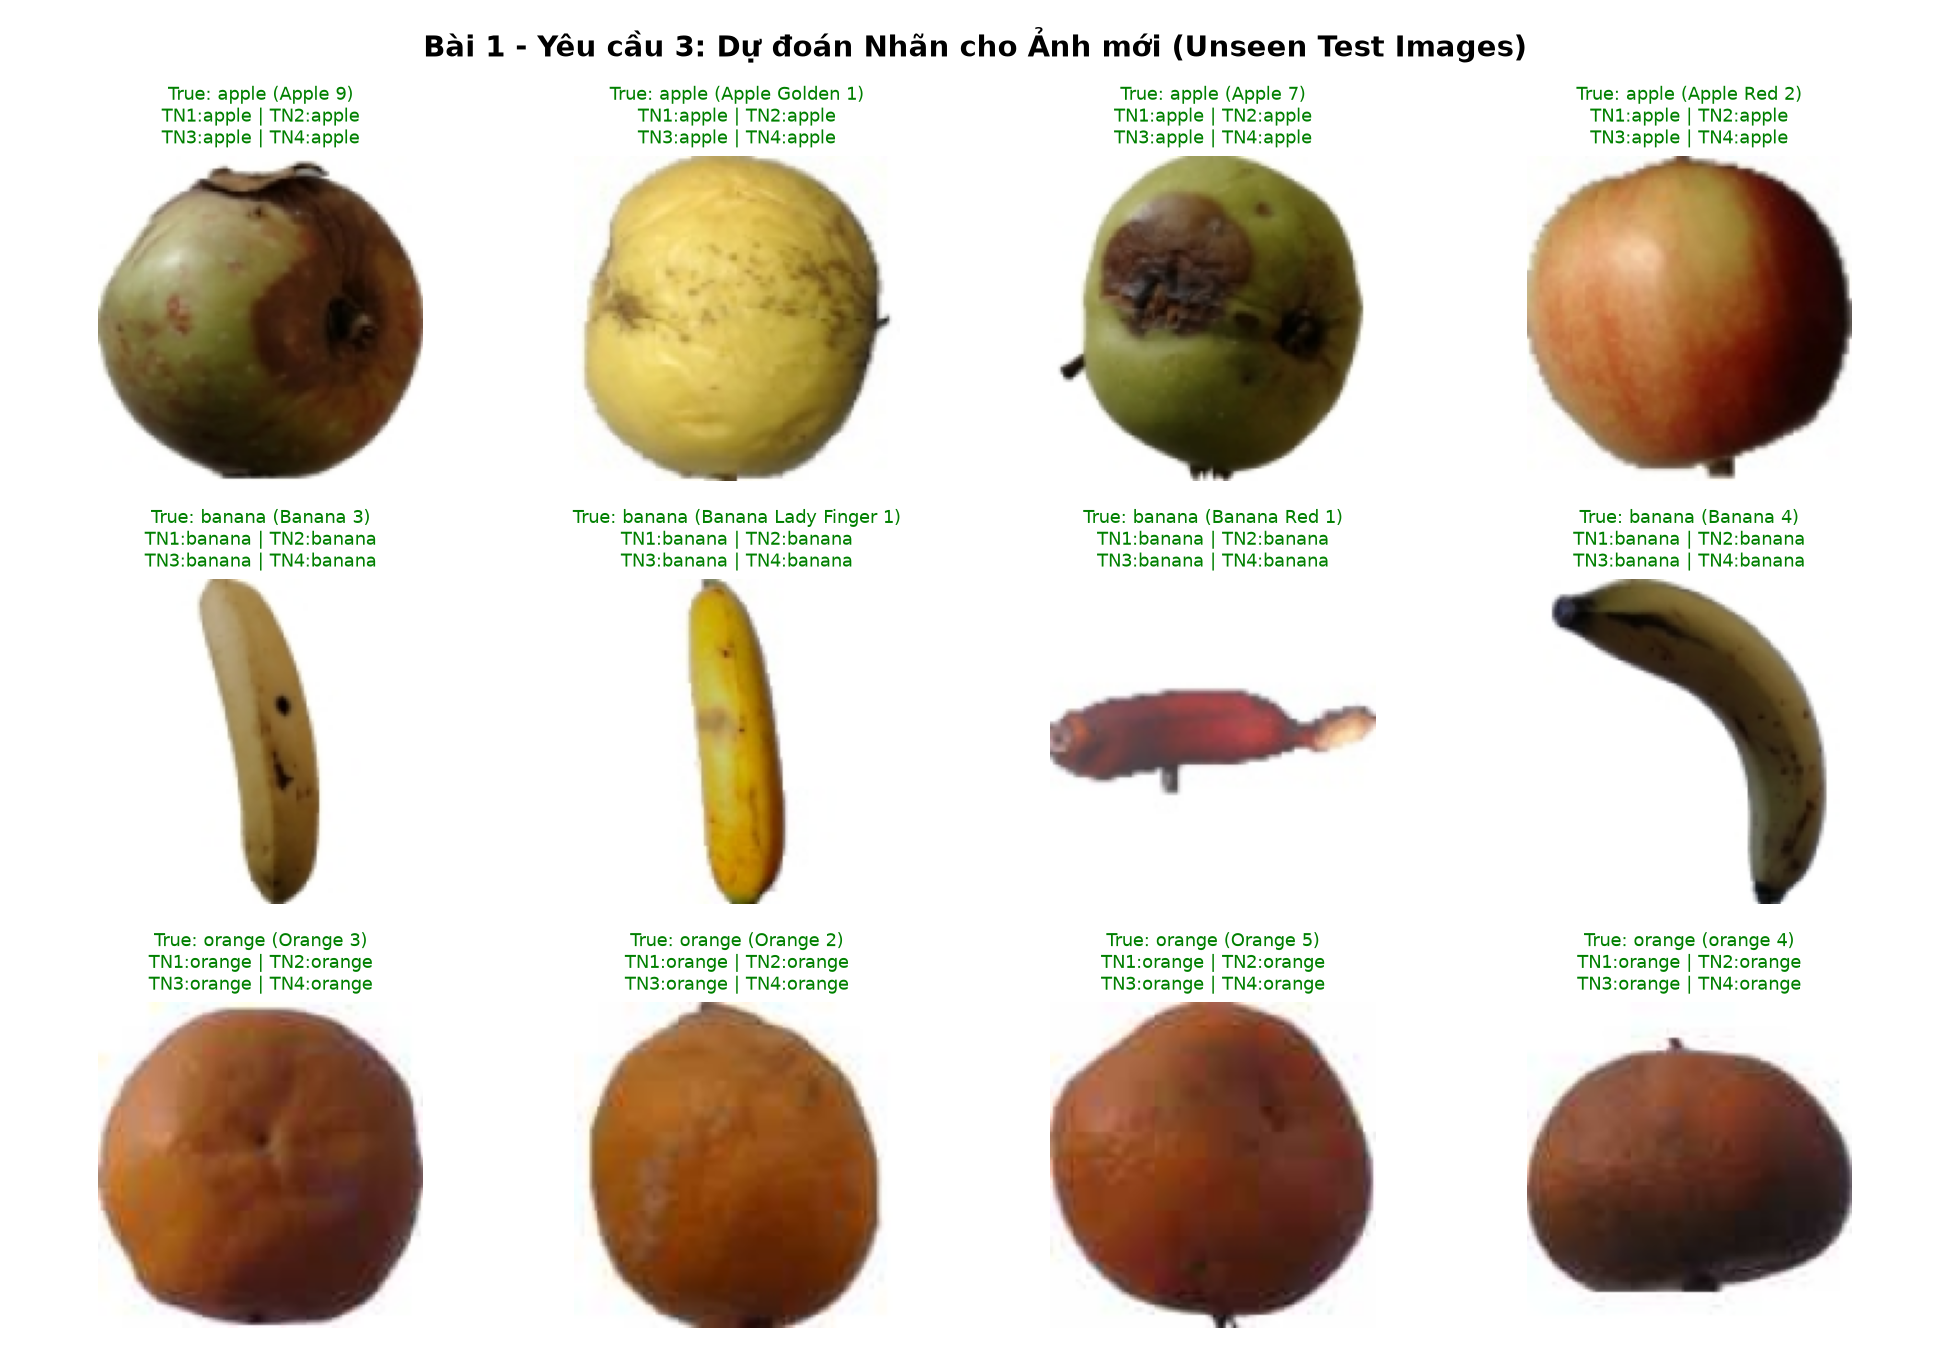

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

df_unseen = pd.read_csv("outputs/bai1/bai1_unseen_predictions.csv")
print("=== DỰ ĐOÁN NHÃN CHO ẢNH MỚI (UNSEEN IMAGES) ===")
print(df_unseen[["sub_folder", "true_label", "TN1_KNN_RGB", "TN2_KNN_HSV", "TN3_SVM_HistHSV", "TN4_SVM_All"]].to_string(index=False))

img = mpimg.imread("outputs/bai1/fig5_unseen_predictions.png")
plt.figure(figsize=(13, 9))
plt.imshow(img)
plt.axis("off")
plt.show()